# Heating-Aware QEC Compilation for a 1D QCCD Architecture

**HEM3 demo** — from a QEC circuit to a logical error rate, with every ion's motional heating tracked along the way.

```
QEC circuit (transport-free DSL)          circuits/<code>.py
        |
        |  Step 1  parse -> dependency DAG
        |  Step 2  compile -> transport-level instructions
        |          (split / shuttle / merge / swap / gate / cool)
        |          + per-ion phonon tracking
        |  Step 3  recompile -> Stim circuit (detectors + observable)
        |  Step 4  noise injection (gate errors from tracked phonons)
        |  Step 5  MWPM decoding
        v
logical error rate p_L
```

Everything below runs live on a laptop. Code distance d = 3, three syndrome-measurement rounds.

In [1]:
import sys, math
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for sub in ('src', 'circuits', 'experiments'):
    sys.path.insert(0, str(REPO / sub))

import numpy as np
import matplotlib.pyplot as plt
import stim
import pymatching

from qccd_parser import parse
from dag_builder import DAGBuilder
from qccd_compiler import QCCDArchitecture, QCCDCompiler, CompilerConfig
from stim_recompiler import recompile_multi_round
from parallel_estimator import ParallelEstimator
from ion_timeline import gaps_from_compile_results
from pauli_lookup import PauliErrorLookup
from exp_noise_injection import (
    phonon_to_pauli_lookup_rates,
    inject_noise_approach_b,
    inject_per_ion_idle,
    default_noise_params,
)
from exp_distance_scan import DISTANCE_CIRCUITS
from exp_multi_round import placement_greedy_alt
from formatter import format_op_summary

PAULI_LOOKUP = PauliErrorLookup()
print('Setup OK — repo root:', REPO.name)

Setup OK — repo root: qccd-simulator


## Step 1 — Input: a QEC circuit with no transport in it

The input is a surface-code syndrome-measurement circuit written in a small serial DSL:
reset / single-qubit rotations / Mølmer–Sørensen gates / measure, one instruction per line.
It says nothing about ion movement — deciding the transport is the compiler's job.

In [2]:
D = 3
ROUNDS = 3
FORWARD, REVERSE, OBSERVABLE = DISTANCE_CIRCUITS[D]
fwd_mod = __import__(FORWARD)

print(f'circuit: {FORWARD}  (rotated surface code, d={D})')
print(f'{len(fwd_mod.DATA_QUBITS)} data qubits + {len(fwd_mod.ANCILLA_QUBITS)} reused ancilla')
print()
print('\n'.join(fwd_mod.CIRCUIT.strip().splitlines()[:14]))
print('...')

circuit: snake_reuse1  (rotated surface code, d=3)
9 data qubits + 1 reused ancilla

# ============================================================
# Qubit Declarations (Dummy Coordinates for Parser)
# ============================================================
QUBIT 0 AT (0, 0)
QUBIT 1 AT (0, 1)
QUBIT 2 AT (0, 2)
QUBIT 3 AT (0, 3)
QUBIT 4 AT (0, 4)
QUBIT 5 AT (0, 5)
QUBIT 6 AT (0, 6)
QUBIT 7 AT (0, 7)
QUBIT 8 AT (0, 8)
QUBIT 9 AT (2, 0)

...


## Step 2 — Compile to transport-level instructions

The architecture is a 1D zone array `M-M-M-L-M-M-M`: one laser-interaction zone (LIZ) in the middle,
memory zones on both sides. The compiler plans every split, shuttle, merge, and in-zone swap needed
to bring each gate's ions into the LIZ, then schedules the instructions in parallel.

While planning, it also integrates a heating model: every transport primitive and every microsecond
of waiting adds phonons, per ion, per mode.

In [3]:
def compile_rounds(cfg_kwargs, rounds=ROUNDS):
    half = (len(fwd_mod.DATA_QUBITS) + 1) // 2
    mem_cap = max(20, half + len(fwd_mod.ANCILLA_QUBITS) + 4)
    arch = QCCDArchitecture.simple_mlm(liz_capacity=4, memory_capacity=mem_cap)
    placement = placement_greedy_alt(
        fwd_mod.DATA_QUBITS, fwd_mod.ANCILLA_QUBITS, fwd_mod)
    cfg = CompilerConfig(**cfg_kwargs)
    results, zone_contents = [], None
    for r in range(1, rounds + 1):
        name = FORWARD if r % 2 == 1 else REVERSE
        m = __import__(name)
        dag = DAGBuilder(parse(m.CIRCUIT), stabilizer_parallel=False).build()
        if zone_contents is not None:
            placement = {ion: z for z in sorted(zone_contents)
                         for ion in zone_contents[z]}
        cr = QCCDCompiler(arch, config=cfg).compile(dag, placement)
        results.append(cr)
        placement, zone_contents = cr.final_placement, cr.final_zone_contents
    return results

baseline = compile_rounds({})

print('instruction counts, round 1:', baseline[0].stats)
print()
print('first native instructions:')
for i, op in enumerate(baseline[0].flat_ops[:8]):
    print(f'  {i}: {format_op_summary(op)}')

pe = ParallelEstimator()
round_ms = [pe.estimate(cr.timesteps).total_time / 1000 for cr in baseline]
print()
print('estimated wall time per round [ms]:', ['%.1f' % m for m in round_ms])

instruction counts, round 1: {'gates': 152, 'shuttles': 49, 'swaps': 24, 'splits': 81, 'merges': 81, 'cools': 0, 'timesteps': 308}

first native instructions:
  0: Split(ion3) z1->z2
  1: Shuttle(ion9) z2->(3, 0)
  2: Merge z2+z3
  3: Reset(9) z3
  4: Split(ion0) z5->z4
  5: Shuttle(ion0) z4->(3, 1)
  6: Merge z3+z4
  7: R(0) z3

estimated wall time per round [ms]: ['26.9', '29.7', '27.6']


## Step 3 — The heating the circuit never asked for

The compiler records each ion's phonon occupation at every two-qubit gate.
Plotted over the gate sequence, the cost of transport becomes visible:
heating accumulates within every round, and two-qubit gates get noisier as $\bar{n}$ grows.

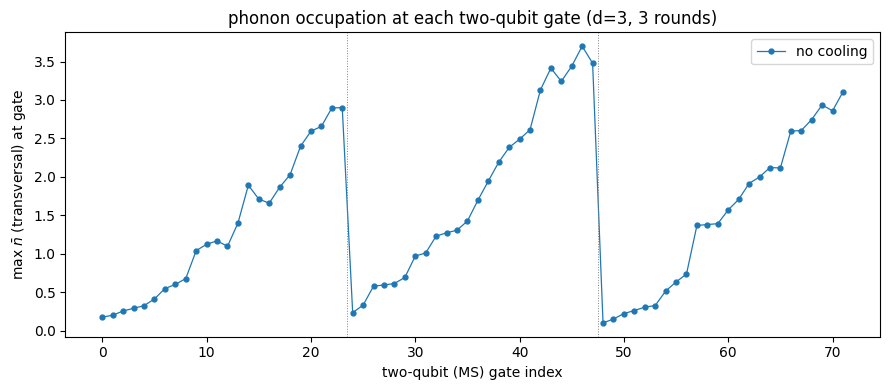

In [4]:
def gate_series(results):
    ys, bounds = [], []
    for cr in results:
        gates = (cr.phonon_data or {}).get('at_gates', [])
        for g in gates:
            ys.append(max(p[1] for p in g['phonons'].values()))
        bounds.append(len(ys))
    return ys, bounds[:-1]

y_base, round_bounds = gate_series(baseline)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(y_base, 'o-', ms=3.5, lw=0.9, color='tab:blue', label='no cooling')
for b in round_bounds:
    ax.axvline(b - 0.5, color='gray', ls=':', lw=0.7)
ax.set_xlabel('two-qubit (MS) gate index')
ax.set_ylabel(r'max $\bar{n}$ (transversal) at gate')
ax.set_title(f'phonon occupation at each two-qubit gate (d={D}, {ROUNDS} rounds)')
ax.legend()
plt.tight_layout()
plt.show()

## Step 4 — Cooling is a compiler policy: one line of configuration

Cooling enters the pipeline as an abstract instruction — a `Cool` operation with a duration and a
residual occupation $\bar{n}_{res}$ — and *when* to issue it is a compiler policy.
The simplest policy: before each two-qubit gate, cool the chain in the LIZ if its phonon
occupation exceeds a threshold $\theta$.

The compiler supports several policies (threshold-triggered, predictive, merge-averaged,
isolation-based recooling); they are all fields of `CompilerConfig`.

cooling operations inserted: 11
wall time per round [ms]:     ['28.1', '31.0', '29.0']  (no cooling: ['26.9', '29.7', '27.6'] )


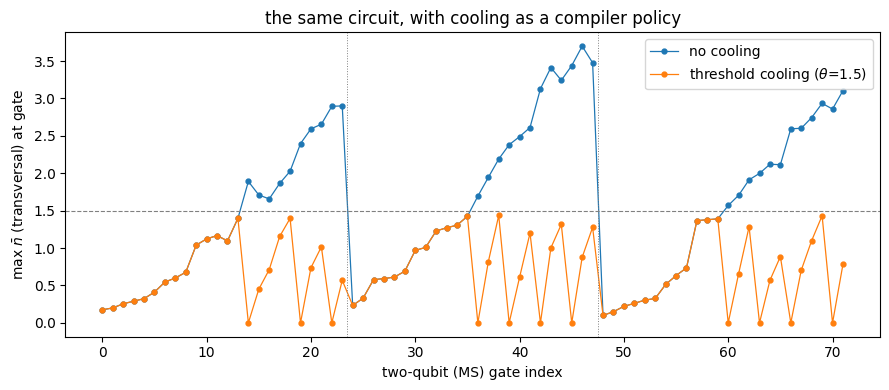

In [5]:
THETA = 1.5
cooled = compile_rounds({'cool_threshold_transversal': THETA})

n_cools = sum(cr.stats.get('cools', 0) for cr in cooled)
round_ms_cooled = [pe.estimate(cr.timesteps).total_time / 1000 for cr in cooled]
print(f'cooling operations inserted: {n_cools}')
print('wall time per round [ms]:    ', ['%.1f' % m for m in round_ms_cooled],
      ' (no cooling:', ['%.1f' % m for m in round_ms], ')')

y_cool, _ = gate_series(cooled)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(y_base, 'o-', ms=3.5, lw=0.9, color='tab:blue', label='no cooling')
ax.plot(y_cool, 'o-', ms=3.5, lw=0.9, color='tab:orange',
        label=f'threshold cooling ($\\theta$={THETA})')
ax.axhline(THETA, color='gray', ls='--', lw=0.8)
for b in round_bounds:
    ax.axvline(b - 0.5, color='gray', ls=':', lw=0.7)
ax.set_xlabel('two-qubit (MS) gate index')
ax.set_ylabel(r'max $\bar{n}$ (transversal) at gate')
ax.set_title('the same circuit, with cooling as a compiler policy')
ax.legend()
plt.tight_layout()
plt.show()

## Step 5 — From phonons to a logical error rate

The compiled rounds are recompiled into a Stim circuit (detectors and the logical observable
included), and noise is injected from the tracked phonons: each MS gate receives a two-qubit Pauli
channel looked up from its recorded $\bar{n}$, and every idle gap contributes per-ion dephasing.
Minimum-weight perfect matching (PyMatching) then decodes the samples.

In [6]:
def run_pl(results, shots, seed=42):
    circuit = recompile_multi_round(results, observable_column=OBSERVABLE)
    all_gates = []
    for cr in results:
        all_gates.extend((cr.phonon_data or {}).get('at_gates', []))
    anchor_ops, gaps = gaps_from_compile_results(results)
    rates = phonon_to_pauli_lookup_rates(
        all_gates, PAULI_LOOKUP, mode='strict', warn_on_clip=False)
    params = default_noise_params()
    noisy = inject_noise_approach_b(circuit, rates, params, include_idle=False)
    noisy = inject_per_ion_idle(noisy, anchor_ops, gaps, params)
    dem = noisy.detector_error_model(
        decompose_errors=True, approximate_disjoint_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(dem)
    det, obs = noisy.compile_detector_sampler(seed=seed).sample(
        shots, separate_observables=True)
    pred = matcher.decode_batch(det)
    n_err = int(np.any(pred != obs, axis=1).sum())
    return n_err / shots, n_err

SHOTS = 50_000
for label, res in (('no cooling   ', baseline),
                   (f'cooled θ={THETA}  ', cooled)):
    p_l, n_err = run_pl(res, SHOTS)
    se = math.sqrt(p_l * (1 - p_l) / SHOTS)
    print(f'{label}: p_L = {p_l:.4f} ± {se:.4f}   ({n_err}/{SHOTS})')

no cooling   : p_L = 0.0177 ± 0.0006   (885/50000)
cooled θ=1.5  : p_L = 0.0079 ± 0.0004   (394/50000)


## Step 6 — What this machinery shows at scale (precomputed)

The live run above is d = 3 with the simplest policy. The paper runs the same pipeline at
d = 3 / 5 / 7 across cooling policies and abstract cooling parameters $(t_{cool}, \bar{n}_{res})$.
Two headline results:

- **Distance scaling is decided by the cooling policy.** With threshold-based policies operating
  within the legal cooling rules, the logical error rate improves with distance
  ($\Lambda_{3,5} = 1.93$, $\Lambda_{5,7} = 2.77$ for isolation-based recooling at $\theta = 1.5$;
  $3.40$ and $4.16$ with a two-threshold variant). Without cooling, larger codes are *worse*.
- **The requirement on the cooling primitive is a residual occupation $\bar{n}_{res} \lesssim 1$**,
  while the cooling duration stays non-dominant up to about 1 ms. This is a statement about the
  abstract cooling condition; any physical scheme inside that region suffices.

The figure below is the policy trade-off from the paper (p_L versus time overhead across five
cooling strategies):

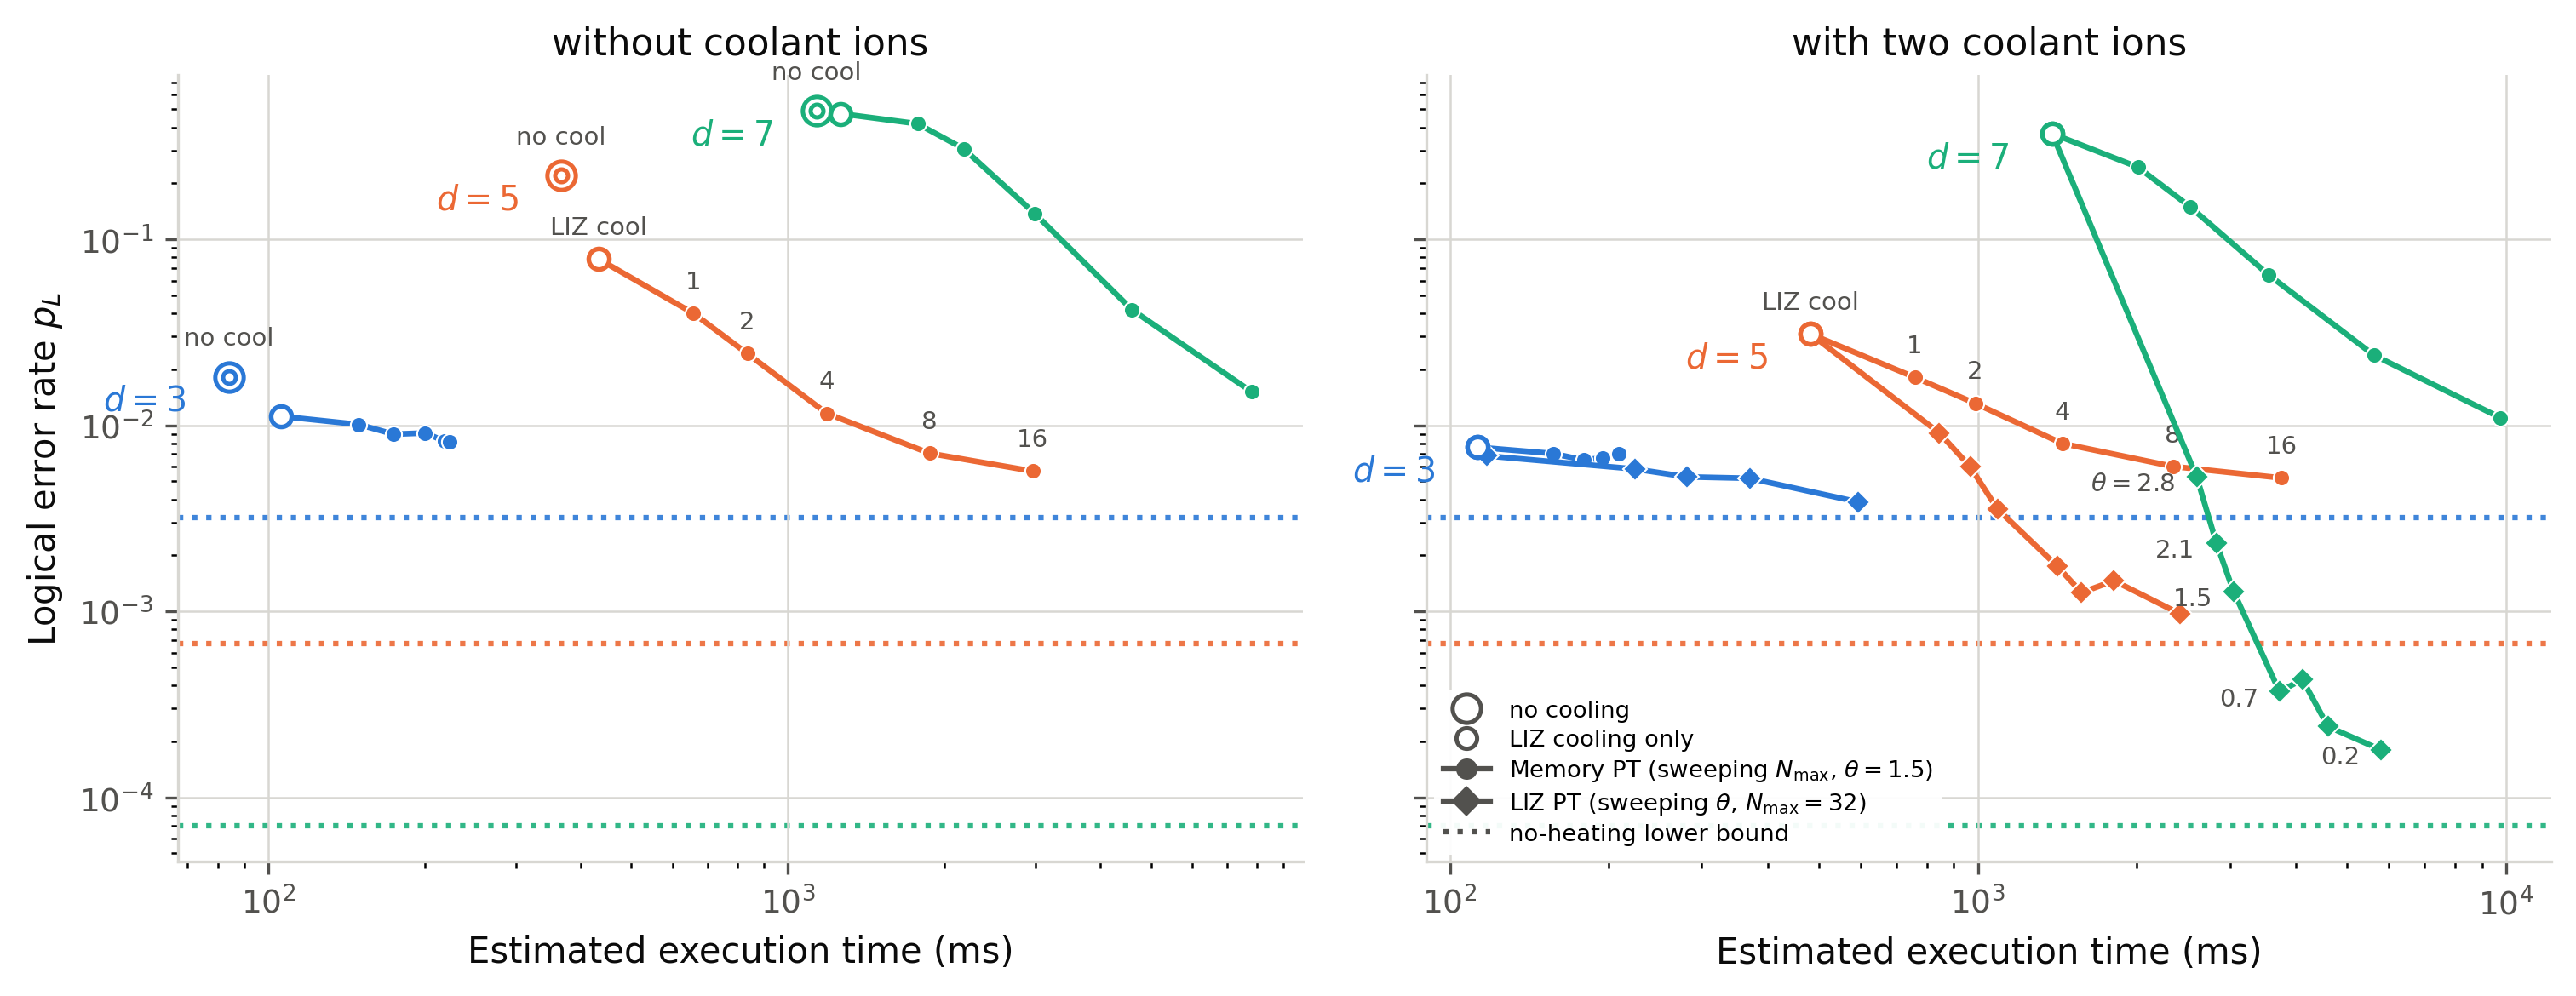

In [7]:
from IPython.display import Image, display
display(Image(filename=str(
    REPO / 'plots' / 'strategy_tradeoff_1103' / 'pl_vs_time_strategies.png'),
    width=760))

## Try it on your own code

The pipeline is code-agnostic: one file `circuits/<code>.py` (stabilizer-explicit, single reused
ancilla, serial) is the only thing a new QEC code needs.

- `notebooks/qec_simulation_walkthrough.ipynb` walks through adding a new code, with the Steane
  [[7,1,3]] code generated end-to-end from its stabilizer list via Stim.
- CLI equivalents: `experiments/exp_distance_scan.py` (distance sweeps),
  `experiments/exp_cooling_pl.py` (cooling-policy comparisons).

Questions and collaboration ideas are welcome — that is what this hackathon is for.